# Exploratory Data Analysis: Auto MPG Dataset

**Dataset:** [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) from the UCI Machine Learning Repository
(listed under *Machine Learning* in [Awesome Public Datasets](https://github.com/awesomedata/awesome-public-datasets)).
It describes **398 cars** from model years 1970 to 1982 with **9 attributes**:

| Attribute | Type | Description |
|---|---|---|
| `mpg` | numerical (continuous) | fuel economy, miles per US gallon |
| `displacement` | numerical (continuous) | engine displacement, cubic inches |
| `horsepower` | numerical (continuous) | engine power, hp (6 missing values) |
| `weight` | numerical (continuous) | vehicle weight, lbs |
| `acceleration` | numerical (continuous) | seconds to go from 0 to 60 mph |
| `model_year` | numerical (discrete) | model year, 70 to 82 (i.e. 1970 to 1982) |
| `cylinders` | categorical (ordinal) | number of cylinders: 3, 4, 5, 6, 8 |
| `origin` | categorical (nominal) | 1 = USA, 2 = Europe, 3 = Japan |
| `car_name` | categorical (nominal, unique ID) | car name; we take the first word as `make` |

### Approach (following the NIST/SEMATECH *e-Handbook*, Chapter 1: EDA)

The [NIST handbook](https://www.itl.nist.gov/div898/handbook/eda/eda.htm) describes EDA as letting the data
show its structure *before* we impose a model on it. It relies mostly on **graphics**, which reveal
things summary numbers hide. The handbook's goals guide this notebook:

1. **Get to know the data**: location, spread, shape of the distribution, outliers.
2. **Check the underlying assumptions**: random sampling, fixed location, fixed variation, fixed distribution
   (the *4-plot*).
3. **Find which variables matter** and how they relate to each other: scatter plot matrix, correlation,
   group comparisons.

Sections: (1) loading and cleaning; (2) summary statistics; (3) one-variable distributions: histograms and bar charts;
(4) all variables in a single box plot; (5) NIST 4-plot for the response variable `mpg`; (6) pairs of numerical variables
(scatter plot matrix); (7) categorical vs categorical; (8) categorical vs numerical; (9) conclusions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visual system: recessive grid, thin marks, fixed categorical order (never cycled)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2b29", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlesize": 11,
})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3
ORIGIN_COLORS = {"USA": BLUE, "Europe": ORANGE, "Japan": AQUA}
ORIGIN_ORDER = ["USA", "Europe", "Japan"]
CYL_ORDER = [3, 4, 5, 6, 8]
CYL_COLORS = dict(zip(CYL_ORDER, sns.light_palette("#1c5aa6", n_colors=7)[2:]))  # sequential: one hue, light -> dark
NEUTRAL = "#8a8984"

## 1. Load and clean the data

In [2]:
cols = ["mpg", "cylinders", "displacement", "horsepower", "weight",
        "acceleration", "model_year", "origin", "car_name"]
df = pd.read_csv("data/auto-mpg.data", sep=r"\s+", names=cols, na_values="?")
print(df.shape)
df.head()

(398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [3]:
df.info()
print("\nMissing values per column:\n", df.isna().sum())
print("\nRows with missing horsepower:", df.loc[df.horsepower.isna(), "car_name"].tolist())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    str    
dtypes: float64(5), int64(3), str(1)
memory usage: 28.1 KB

Missing values per column:
 mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64

Rows with missing horsepower: ['ford pinto', 'ford maverick', 'renault lecar deluxe', 'ford mustang cobra', 'renault 18i', 'amc concord dl']
Duplicate rows: 0


The dataset has **398 rows and 9 columns**. The only data-quality problem is **6 missing `horsepower` values**
(stored as `?` in the raw file). We **keep** these rows for the one-variable summaries of the other columns and
leave them out only of plots that need `horsepower`. There are no duplicate rows.

Cleaning steps:
* map `origin` codes to labels (USA / Europe / Japan),
* treat `cylinders` and `origin` as **ordered categoricals**,
* get `make` from `car_name` and fix its spelling errors (`chevy`, `chevroelt` → `chevrolet`;
  `vw`, `vokswagen` → `volkswagen`; `toyouta` → `toyota`; `maxda` → `mazda`; `mercedes` → `mercedes-benz`).

In [4]:
df["origin"] = pd.Categorical(df["origin"].map({1: "USA", 2: "Europe", 3: "Japan"}),
                              categories=ORIGIN_ORDER, ordered=True)
df["cylinders"] = pd.Categorical(df["cylinders"], categories=CYL_ORDER, ordered=True)
fix = {"chevy": "chevrolet", "chevroelt": "chevrolet", "vw": "volkswagen", "vokswagen": "volkswagen",
       "toyouta": "toyota", "maxda": "mazda", "mercedes": "mercedes-benz", "hi": "international"}
df["make"] = df["car_name"].str.split().str[0].replace(fix)

NUM = ["mpg", "displacement", "horsepower", "weight", "acceleration", "model_year"]
CAT = ["cylinders", "origin", "make"]
print("Numerical:", NUM, "\nCategorical:", CAT, "\nDistinct makes:", df.make.nunique())

Numerical: ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year'] 
Categorical: ['cylinders', 'origin', 'make'] 
Distinct makes: 30


## 2. Summary statistics

In [5]:
def iqr_outliers(s):
    # Tukey's rule (the box-plot rule NIST uses): outside [Q1 - 1.5 IQR, Q3 + 1.5 IQR]
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    return s[(s < lo) | (s > hi)], lo, hi

rows = []
for c in NUM:
    s = df[c]
    out, lo, hi = iqr_outliers(s)
    rows.append({"variable": c, "count": s.count(), "min": s.min(), "max": s.max(),
                 "mean": s.mean(), "median": s.median(), "std": s.std(), "skew": s.skew(),
                 "lower fence": lo, "upper fence": hi, "# outliers": len(out)})
summary = pd.DataFrame(rows).set_index("variable").round(2)
summary

,count,min,max,mean,median,std,skew,lower fence,upper fence,# outliers
variable,,,,,,,,,,
mpg,398,9.0,46.6,23.51,23.0,7.82,0.46,0.25,46.25,1
displacement,398,68.0,455.0,193.43,148.5,104.27,0.72,-132.38,498.62,0
horsepower,392,46.0,230.0,104.47,93.5,38.49,1.09,-1.50,202.50,10
weight,398,1613.0,5140.0,2970.42,2803.5,846.84,0.53,147.38,5684.38,0
acceleration,398,8.0,24.8,15.57,15.5,2.76,0.28,8.80,22.20,7
model_year,398,70.0,82.0,76.01,76.0,3.70,0.01,64.00,88.00,0


To find **outliers** we use the **1.5 × IQR (Tukey) rule**, which is also how box-plot whiskers are drawn. A
value counts as an outlier if it falls below Q1 − 1.5·IQR or above Q3 + 1.5·IQR. In the table:
* the **mean is above the median** for `mpg`, `displacement`, `horsepower` and `weight`, a sign of **right skew**
  (a long tail of large values);
* `horsepower` (10 high outliers) and `acceleration` (7 outliers on both ends) are the only columns with more than one outlier;
* `displacement`, `weight` and `model_year` have **no** outliers.

## 3. One-variable distributions

### 3a. Histograms of the numerical variables

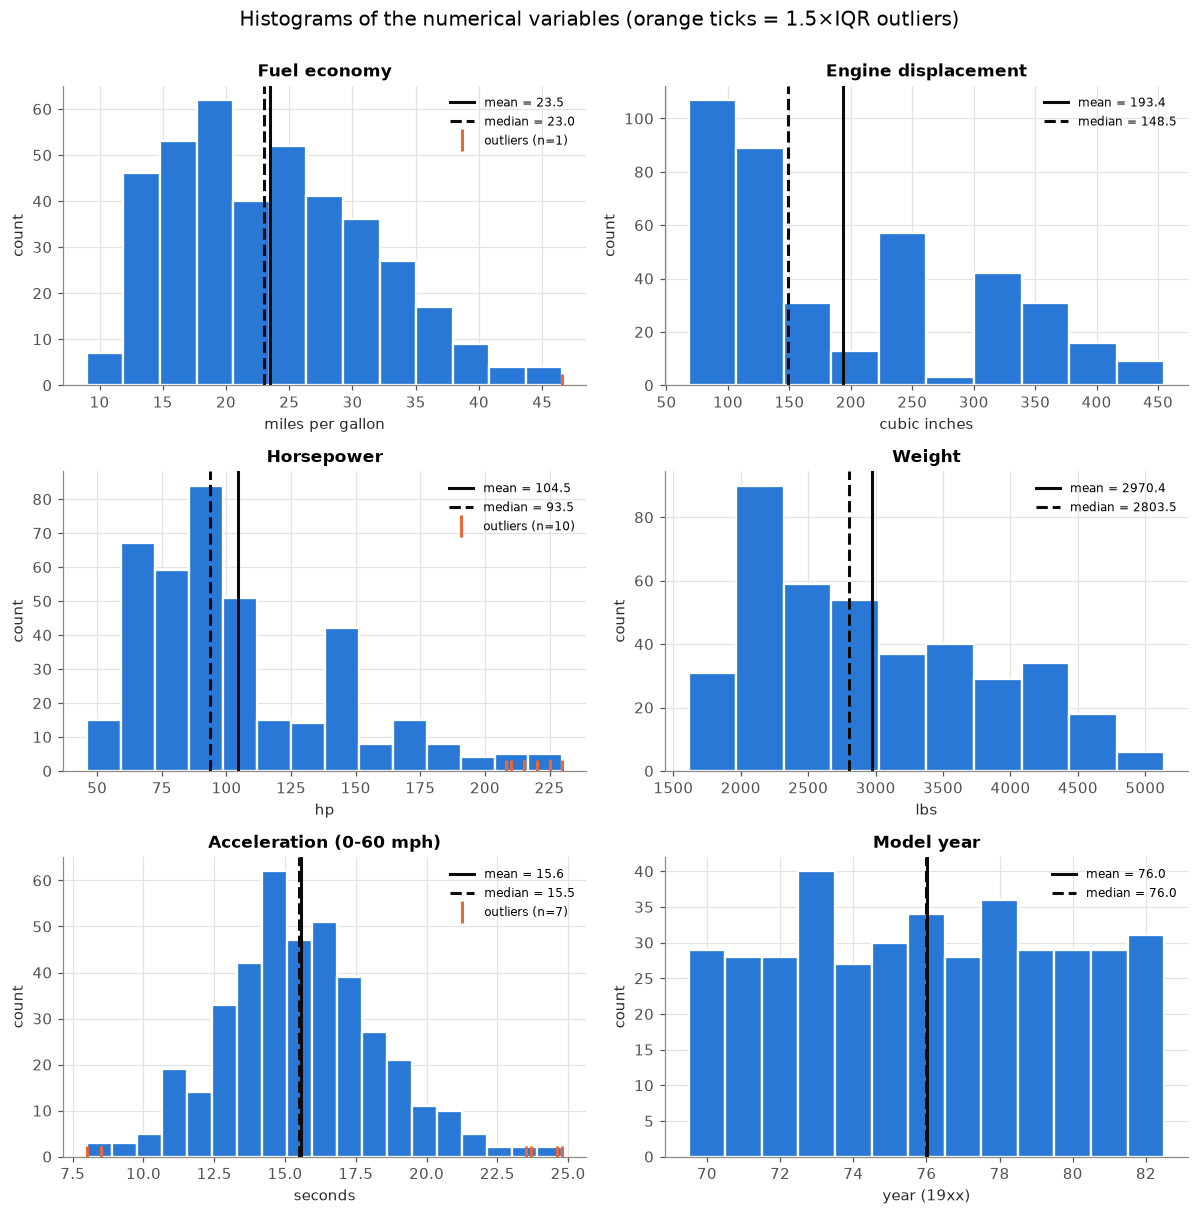

In [6]:
def hist_with_stats(ax, s, title, unit, bins="auto", discrete=False):
    s = s.dropna()
    if discrete:
        bins = np.arange(s.min() - 0.5, s.max() + 1.5, 1)
    ax.hist(s, bins=bins, color=BLUE, edgecolor="white", linewidth=1.5)
    ax.axvline(s.mean(), color="#0b0b0b", lw=2, label=f"mean = {s.mean():.1f}")
    ax.axvline(s.median(), color="#0b0b0b", lw=2, ls="--", label=f"median = {s.median():.1f}")
    out, lo, hi = iqr_outliers(s)
    if len(out):
        ax.plot(out, np.zeros(len(out)), "|", color=ORANGE, ms=14, mew=2, label=f"outliers (n={len(out)})")
    ax.set(title=title, xlabel=unit, ylabel="count")
    ax.legend(frameon=False, fontsize=8)

labels = {"mpg": ("Fuel economy", "miles per gallon"),
          "displacement": ("Engine displacement", "cubic inches"),
          "horsepower": ("Horsepower", "hp"),
          "weight": ("Weight", "lbs"),
          "acceleration": ("Acceleration (0-60 mph)", "seconds"),
          "model_year": ("Model year", "year (19xx)")}
fig, axes = plt.subplots(3, 2, figsize=(11, 11))
for ax, c in zip(axes.flat, NUM):
    hist_with_stats(ax, df[c], *labels[c], discrete=(c == "model_year"))
fig.suptitle("Histograms of the numerical variables (orange ticks = 1.5×IQR outliers)", y=1.0, fontsize=13)
fig.tight_layout()

In [7]:
# Show which cars are the outliers
for c in NUM:
    out, lo, hi = iqr_outliers(df[c])
    if len(out):
        print(f"--- {c}: fences [{lo:.1f}, {hi:.1f}] ---")
        print(df.loc[out.index, ["car_name", "model_year", c]].sort_values(c).to_string(index=False), "\n")

--- mpg: fences [0.2, 46.2] ---
 car_name  model_year  mpg
mazda glc          80 46.6 

--- horsepower: fences [-1.5, 202.5] ---
                    car_name  model_year  horsepower
             mercury marquis          72       208.0
                  dodge d200          70       210.0
           plymouth fury iii          70       215.0
                   ford f250          70       215.0
chrysler new yorker brougham          73       215.0
            chevrolet impala          70       220.0
            pontiac catalina          70       225.0
     buick estate wagon (sw)          70       225.0
    buick electra 225 custom          73       225.0
          pontiac grand prix          73       230.0 

--- acceleration: fences [8.8, 22.2] ---
          car_name  model_year  acceleration
plymouth 'cuda 340          70           8.0
 plymouth fury iii          70           8.5
amc ambassador dpl          70           8.5
 volkswagen type 3          72          23.5
vw dasher (diesel)  

**What each histogram shows** (min / max / mean / median / outliers):

* **`mpg`**: min **9.0**, max **46.6**, mean **23.5**, median **23.0**, std 7.8. Mildly right-skewed
  (skew 0.46): most cars get 15–30 mpg, with a thin tail of very efficient cars. **One outlier**: the
  *Mazda GLC* (1980) at 46.6 mpg, just above the upper fence of 46.25. It is a real economy car, not a data error.
* **`displacement`**: min **68**, max **455** cu in, mean **193.4**, median **148.5**. Clearly
  **multi-modal**: one big group of small engines (~85–150 cu in, mostly 4-cylinder) and smaller groups near 250
  (6-cyl) and 300–400 (V8). Because the mean is far above the median, the distribution is right-skewed (0.72), but there are **no IQR outliers**.
  A single summary number describes this column poorly. The clusters come from the `cylinders` category (see §8).
* **`horsepower`** (392 non-missing): min **46**, max **230** hp, mean **104.5**, median **93.5**. The most skewed
  column (skew 1.09). **10 high outliers** (208–230 hp), all large early-1970s American V8s (e.g. *Pontiac Grand
  Prix* 230 hp, *Buick Electra 225*, *Chevrolet Impala*, *Ford F250*). These are real values, not errors.
* **`weight`**: min **1,613**, max **5,140** lbs, mean **2,970**, median **2,804**. Right-skewed
  (0.53) with a wide spread (std 847); **no outliers**.
* **`acceleration`**: min **8.0**, max **24.8** s, mean **15.6**, median **15.5**. The most symmetric,
  bell-shaped column (skew 0.28); mean and median are nearly the same. **7 outliers on both ends**: very quick
  muscle cars (*Plymouth 'Cuda 340*, 8.0 s) and very slow European diesels/economy cars (*Peugeot 504*, 24.8 s;
  *VW Pickup*, 24.6 s).
* **`model_year`**: min **70**, max **82**, mean **76.0**, median **76.0**. Close to **uniform**: each year
  has roughly 27–40 cars, so the sample covers the period evenly. No outliers.

### 3b. Bar charts of the categorical variables

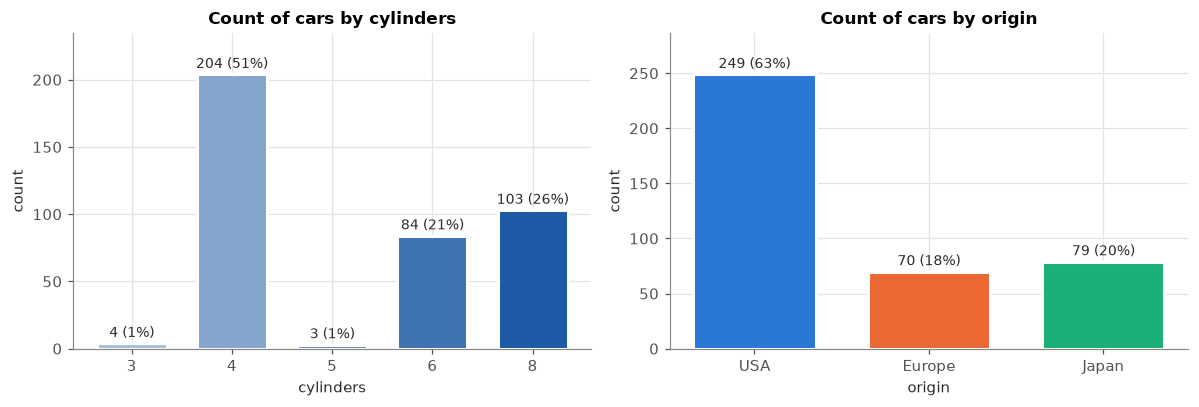

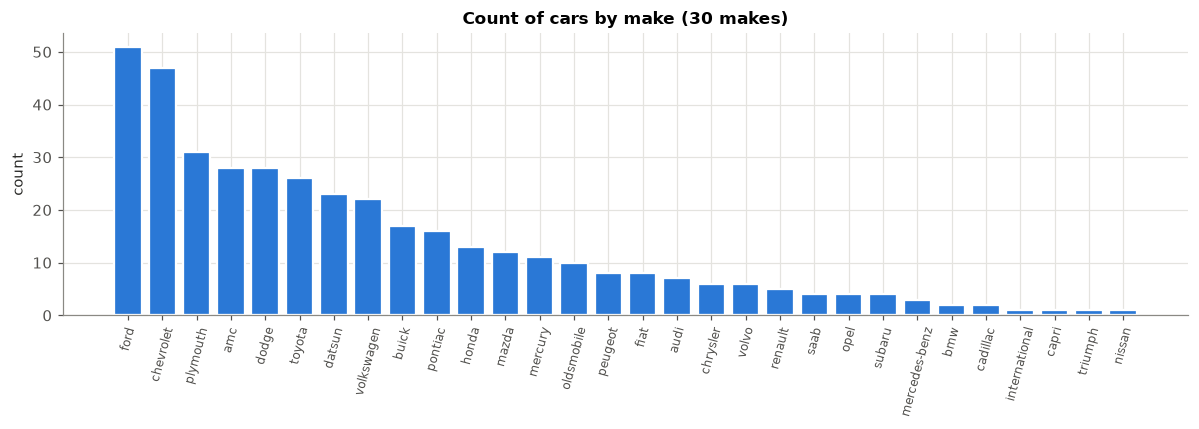

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, c, colors in [(axes[0], "cylinders", [CYL_COLORS[k] for k in CYL_ORDER]),
                      (axes[1], "origin", [ORIGIN_COLORS[k] for k in ORIGIN_ORDER])]:
    vc = df[c].value_counts().sort_index()
    bars = ax.bar(vc.index.astype(str), vc.values, color=colors, edgecolor="white", linewidth=2, width=0.7)
    ax.bar_label(bars, labels=[f"{v} ({v/len(df):.0%})" for v in vc.values], fontsize=9, color="#2b2b29", padding=2)
    ax.set(title=f"Count of cars by {c}", xlabel=c, ylabel="count")
    ax.set_ylim(0, vc.max() * 1.15)
fig.tight_layout()

fig, ax = plt.subplots(figsize=(11, 4))
mk = df.make.value_counts()
ax.bar(mk.index, mk.values, color=BLUE, edgecolor="white", linewidth=1.5)
ax.set(title=f"Count of cars by make ({df.make.nunique()} makes)", ylabel="count")
ax.tick_params(axis="x", rotation=75, labelsize=8)
fig.tight_layout()

In [9]:
display(df.make.value_counts().describe().round(1).to_frame("cars per make").T)

,count,mean,std,min,25%,50%,75%,max
cars per make,30.0,13.3,13.4,1.0,4.0,8.0,20.8,51.0


For categorical variables, max/min/mean/median of the *values* have no meaning, so we describe the **category counts** instead:

* **`cylinders`**: 4-cylinder is the **mode** (204 cars, 51%), then 8-cyl (103, 26%) and 6-cyl (84, 21%).
  **3-cylinder (4 cars, all Mazda rotary) and 5-cylinder (3 cars, Audi/Mercedes diesels) are rare categories**, the
  categorical version of outliers. Statistics for those groups rest on very few cars.
* **`origin`**: unbalanced. **USA 249 (63%)**, Japan 79 (20%), Europe 70 (18%). Overall averages are therefore
  pulled toward American cars.
* **`make`**: 30 makes after cleaning. Ford (51), Chevrolet (47) and Plymouth (31) have the most cars; four makes
  (Triumph, Nissan, International, Capri) have only one car. Counts per make range from 1 to 51 (mean 13.3, median 8),
  a long-tailed distribution. `car_name` itself is almost unique (305 distinct names), so it works as an
  identifier, not as something to analyze.

## 4. All variables side by side: a single box plot

The variables use very different units (weight is in the thousands, acceleration is about 15), so a raw box plot
would squash everything except `weight`. To put them **side by side on one axis**, we standardize each variable to a
**z-score** (mean 0, std 1). This keeps each distribution's shape, skew and outliers and makes them comparable. Next
to it is the same plot on raw values with a log axis.

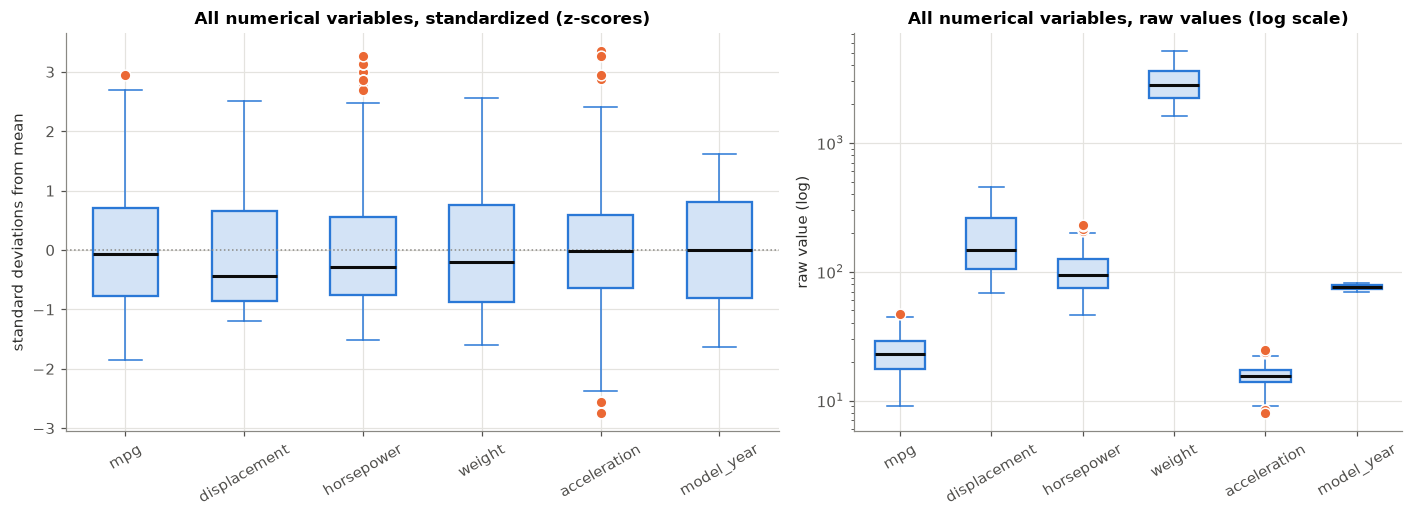

In [10]:
z = (df[NUM] - df[NUM].mean()) / df[NUM].std()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
flier = dict(marker="o", markerfacecolor=ORANGE, markeredgecolor="white", markersize=7)
box = dict(facecolor="#d3e3f6", edgecolor=BLUE, linewidth=1.5)
kw = dict(patch_artist=True, boxprops=box, flierprops=flier, widths=0.55,
          medianprops=dict(color="#0b0b0b", lw=2), whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
axes[0].boxplot([z[c].dropna() for c in NUM], tick_labels=NUM, **kw)
axes[0].axhline(0, color=NEUTRAL, lw=1, ls=":")
axes[0].set(title="All numerical variables, standardized (z-scores)", ylabel="standard deviations from mean")
axes[1].boxplot([df[c].dropna() for c in NUM], tick_labels=NUM, **kw)
axes[1].set_yscale("log")
axes[1].set(title="All numerical variables, raw values (log scale)", ylabel="raw value (log)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()

In the box plot:
* **`horsepower`** has the longest upper whisker and the most outliers (10 above +2.5 σ). It is the most right-skewed column.
* **`acceleration`** is the only column with outliers **on both sides**, which fits its symmetric, bell-shaped histogram.
* **`mpg`** has a single outlier at the top (Mazda GLC, about +2.9 σ).
* In **`displacement`** the median line sits low in the box: half the cars are packed into a narrow band of
  small engines and the other half spread over a much wider range.
* **`model_year`** is evenly spread with a centered median, as expected for a near-uniform variable.

## 5. NIST 4-plot for `mpg`

The NIST handbook's main tool for checking the **four underlying assumptions** (random draws, fixed location,
fixed variation, fixed distribution) is the **4-plot**: run sequence plot, lag plot, histogram, and normal
probability plot. We use `mpg` (the natural response variable) in the row order of the file, which is sorted by
model year.

Shapiro-Wilk normality test: W = 0.968, p = 1.18e-07


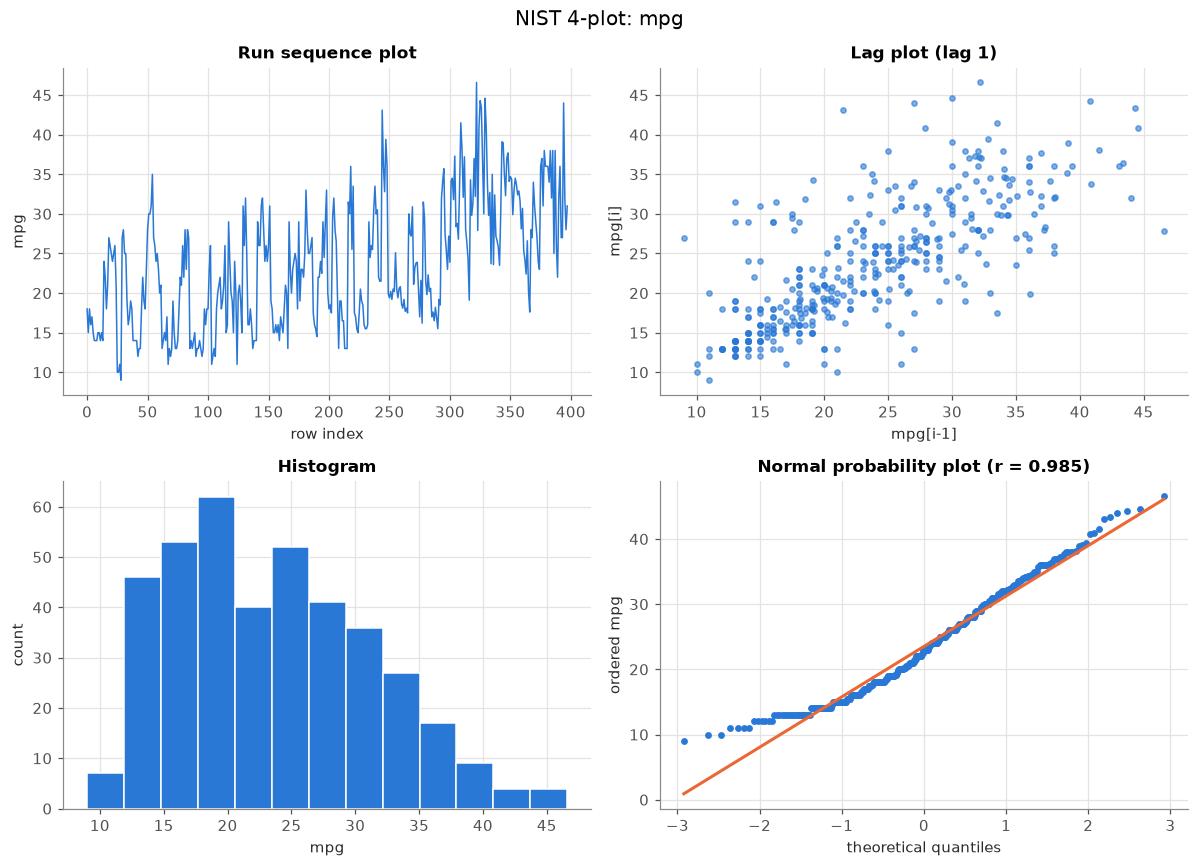

In [11]:
y = df["mpg"].values
fig, ax = plt.subplots(2, 2, figsize=(11, 8))
ax[0, 0].plot(y, color=BLUE, lw=1); ax[0, 0].set(title="Run sequence plot", xlabel="row index", ylabel="mpg")
ax[0, 1].scatter(y[:-1], y[1:], s=12, color=BLUE, alpha=0.6); ax[0, 1].set(title="Lag plot (lag 1)", xlabel="mpg[i-1]", ylabel="mpg[i]")
ax[1, 0].hist(y, bins="auto", color=BLUE, edgecolor="white"); ax[1, 0].set(title="Histogram", xlabel="mpg", ylabel="count")
(osm, osr), (slope, icpt, r) = stats.probplot(y, dist="norm")
ax[1, 1].scatter(osm, osr, s=12, color=BLUE); ax[1, 1].plot(osm, slope * osm + icpt, color=ORANGE, lw=2)
ax[1, 1].set(title=f"Normal probability plot (r = {r:.3f})", xlabel="theoretical quantiles", ylabel="ordered mpg")
fig.suptitle("NIST 4-plot: mpg", fontsize=13); fig.tight_layout()
print(f"Shapiro-Wilk normality test: W = {stats.shapiro(y).statistic:.3f}, p = {stats.shapiro(y).pvalue:.2e}")

4-plot results:
* **Run sequence:** the level **drifts upward** across the file. Because rows are sorted by model year, this shows
  that fuel economy improves over time. The *fixed location* assumption fails; `mpg` depends on `model_year`.
* **Lag plot:** a positive pattern instead of a random cloud. Neighboring rows are similar because they come
  from the same year (and often the same maker), so the rows are **not random draws** in the order given.
* **Histogram & normal probability plot:** the points curve away from the line at both ends (right skew), and
  Shapiro-Wilk rejects normality. A log transform of `mpg`, or using fuel consumption (gallons per mile),
  would make it closer to normal before fitting a model.

## 6. Pairs of numerical variables: scatter plot matrix

The matrix below uses **only the numerical variables**. Histograms are on the diagonal and each scatter panel
shows one pair of variables.

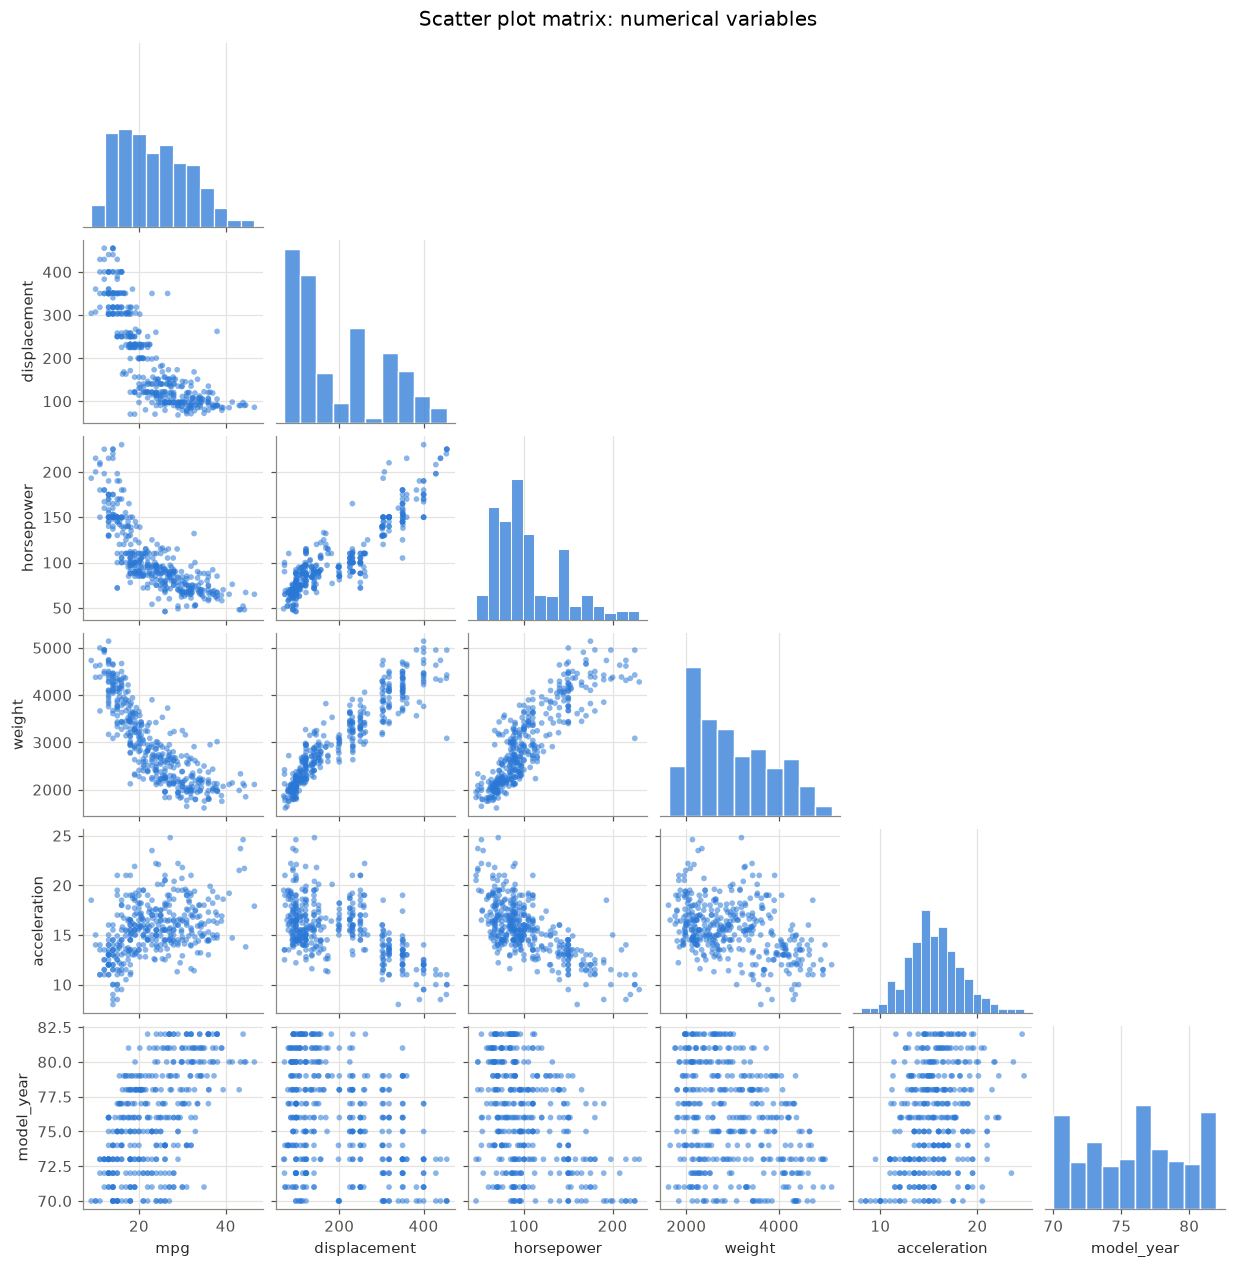

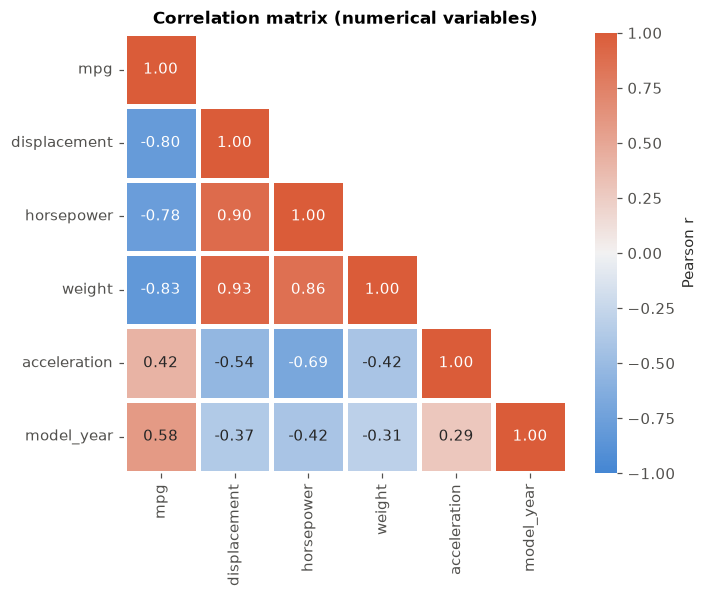

In [12]:
g = sns.pairplot(df[NUM].dropna(), corner=True, height=1.9,
                 plot_kws=dict(s=14, color=BLUE, alpha=0.55, edgecolor="none"),
                 diag_kws=dict(color=BLUE, edgecolor="white"))
g.figure.suptitle("Scatter plot matrix: numerical variables", y=1.01, fontsize=13)
plt.show()

corr = df[NUM].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.2))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap=sns.diverging_palette(250, 20, s=80, l=55, as_cmap=True),
            vmin=-1, vmax=1, center=0, linewidths=2, linecolor="white", ax=ax, cbar_kws={"label": "Pearson r"})
ax.set_title("Correlation matrix (numerical variables)"); ax.grid(False)
plt.show()

What the scatter plot matrix and correlations show:
* **`displacement`, `horsepower` and `weight` measure nearly the same thing** (r = 0.86–0.93), roughly
  "size of car and engine." If all three go into a regression model they will be highly collinear.
* **`mpg` falls steadily as size grows**: r = −0.83 with weight, −0.80 with displacement, −0.78 with
  horsepower. These relationships are **curved, not straight**: mpg drops quickly for light cars and then levels
  off, like an inverse relationship. That again suggests modeling 1/mpg or log(mpg).
* **`acceleration`** is most related to `horsepower` (r = −0.69): more power means fewer seconds to 60 mph.
* **`model_year`** has a moderate positive link with `mpg` (r = 0.58). Cars got more efficient over the period,
  which matches the 1970s oil crises and the CAFE fuel-economy standards introduced in 1978.
* The vertical stripes in several panels come from `model_year` being a whole-number variable, and the clusters in
  `displacement` come from the cylinder groups (see §8).

## 7. Categorical vs categorical

To compare two categorical variables, count how many cars fall into each **combination of categories** (a
**cross-tabulation**, or contingency table) and plot it. We use:
1. a **heatmap of the cross-tab counts**: every cell's size is visible at once;
2. a **100% stacked bar chart**: what share of each origin's cars has each cylinder count;
3. a **chi-square test of independence**: a number for how strongly the two variables are linked.

cylinders,3,4,5,6,8,Total
origin,,,,,,
USA,0,72,0,74,103,249
Europe,0,63,3,4,0,70
Japan,4,69,0,6,0,79
Total,4,204,3,84,103,398


Chi-square = 180.1, dof = 8, p = 9.8e-35, Cramér's V = 0.48


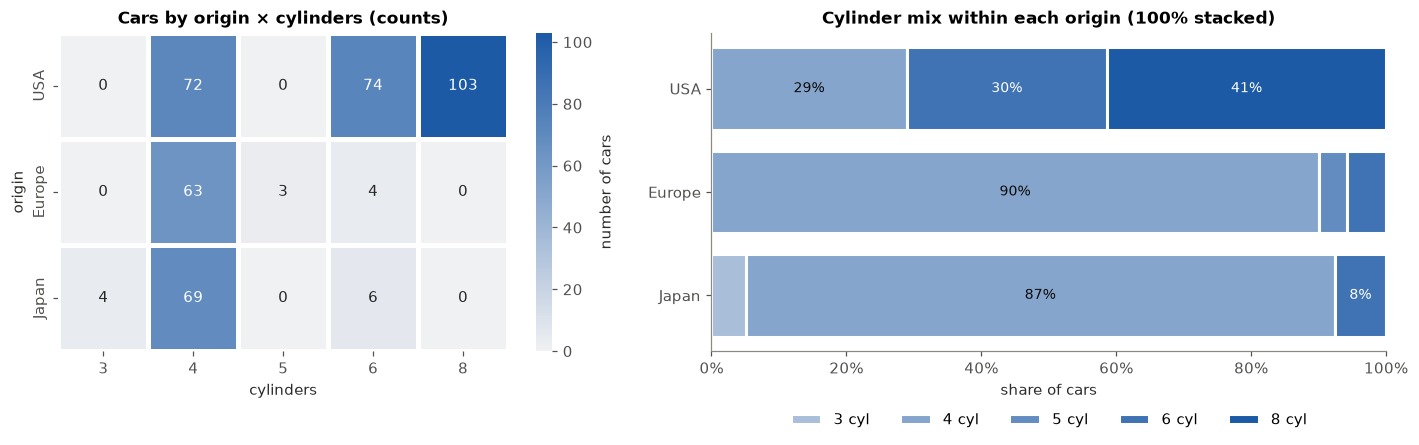

In [13]:
ct = pd.crosstab(df["origin"], df["cylinders"], margins=True, margins_name="Total")
display(ct)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
sns.heatmap(pd.crosstab(df["origin"], df["cylinders"]), annot=True, fmt="d", cmap=sns.light_palette("#1c5aa6", as_cmap=True),
            linewidths=2, linecolor="white", cbar_kws={"label": "number of cars"}, ax=axes[0])
axes[0].set_title("Cars by origin × cylinders (counts)"); axes[0].grid(False)

share = pd.crosstab(df["origin"], df["cylinders"], normalize="index")
left = np.zeros(len(share))
for k in CYL_ORDER:
    axes[1].barh(share.index.astype(str), share[k], left=left, color=CYL_COLORS[k], edgecolor="white", linewidth=2, label=f"{k} cyl")
    for i, v in enumerate(share[k]):
        if v > 0.06:
            axes[1].text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                         color="white" if k >= 6 else "#0b0b0b")
    left += share[k].values
axes[1].invert_yaxis(); axes[1].set_xlim(0, 1); axes[1].grid(False)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[1].set(title="Cylinder mix within each origin (100% stacked)", xlabel="share of cars")
axes[1].legend(ncol=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["origin"], df["cylinders"]))
n = len(df); cramers_v = np.sqrt(chi2 / (n * (min(3, 5) - 1)))
print(f"Chi-square = {chi2:.1f}, dof = {dof}, p = {p:.1e}, Cramér's V = {cramers_v:.2f}")

**`origin` and `cylinders` are strongly linked** (χ² test p ≪ 0.001, Cramér's V ≈ 0.5):
* **Every 8-cylinder car in the dataset is American** (103 of 103), and 71% of American cars have 6 or 8 cylinders.
* European and Japanese cars are **almost all 4-cylinder** (90% and 87%).
* The rare categories each come from one origin: the 3-cylinder rotaries are all Japanese, the 5-cylinders all European.

So `origin` and `cylinders` overlap heavily. Part of any "origin effect" on mpg is really a cylinder/engine-size effect.

### Aggregating one variable by another

Another way to compare variables is to **group the cars by one or two categories and take the average of a third
variable**. Below we compute **mean mpg for each origin × cylinders cell** (a pivot table), and **mean mpg per model year
for each origin**.

cylinders,3,4,5,6,8
origin,,,,,
USA,NaN,27.8,NaN,19.7,15.0
Europe,NaN,28.4,27.4,20.1,NaN
Japan,20.6,31.6,NaN,23.9,NaN


mpg        displacement        horsepower         weight          \
        mean median         mean median       mean median    mean  median   
origin                                                                      
USA     20.1   18.5        245.9  250.0      119.0  105.0  3361.9  3365.0   
Europe  27.9   26.5        109.1  104.5       80.6   76.5  2423.3  2240.0   
Japan   30.5   31.6        102.7   97.0       79.8   75.0  2221.2  2155.0   

       acceleration        model_year         
               mean median       mean median  
origin                                        
USA            15.0   15.0       75.6   76.0  
Europe         16.8   15.7       75.8   76.0  
Japan          16.2   16.4       77.4   78.0

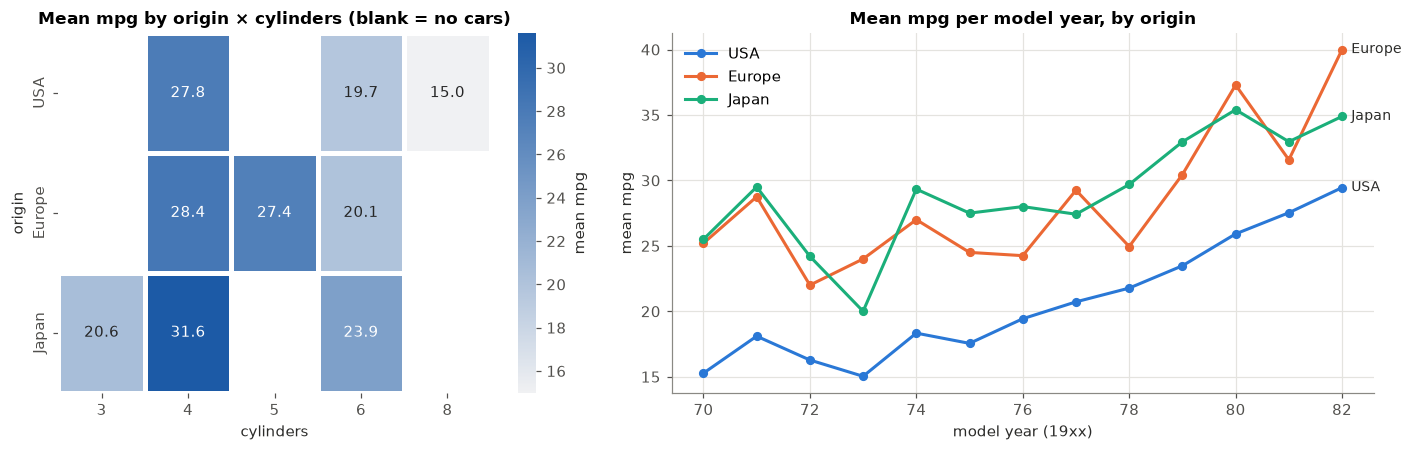

In [14]:
pv = df.pivot_table(index="origin", columns="cylinders", values="mpg", aggfunc="mean", observed=False).round(1)
display(pv)
display(df.groupby("origin", observed=True)[NUM].agg(["mean", "median"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
sns.heatmap(pv, annot=True, fmt=".1f", cmap=sns.light_palette("#1c5aa6", as_cmap=True), linewidths=2, linecolor="white",
            cbar_kws={"label": "mean mpg"}, ax=axes[0])
axes[0].set_title("Mean mpg by origin × cylinders (blank = no cars)"); axes[0].grid(False)

yr = df.groupby(["model_year", "origin"], observed=True)["mpg"].mean().unstack()
for o in ORIGIN_ORDER:
    axes[1].plot(yr.index, yr[o], color=ORIGIN_COLORS[o], lw=2, marker="o", ms=5)
    axes[1].annotate(o, (yr.index[-1], yr[o].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                     color="#2b2b29", va="center", fontsize=9)
axes[1].set(title="Mean mpg per model year, by origin", xlabel="model year (19xx)", ylabel="mean mpg")
axes[1].legend(ORIGIN_ORDER, frameon=False, loc="upper left")
fig.tight_layout()

* Averaged over all cars, **Japanese cars get 30.5 mpg, European 27.9, American 20.1**.
* **Holding cylinders fixed shrinks the gap**: among 4-cylinder cars, US cars average about 27.8 mpg versus about 28.4
  (Europe) and 31.6 (Japan). Most of the overall US deficit comes from the US being the only maker of V6/V8 cars.
* **Every origin improves over time**. US cars go from about 15–18 mpg (1970–73) to about 29 mpg by 1982, with the steepest
  rise after the 1979 oil shock. Japan and Europe stay well ahead of the US in every year; Japan leads Europe in most
  years, but European cars pass it in 1980 and 1982 (small samples of 9 and 2 cars, led by Volkswagen models).

## 8. Categorical vs numerical: color and grouping

To show a **categorical** variable against **numerical** ones we:
1. **color** the points of the scatter plot matrix by a category (`hue = origin`), so each origin's position in
   every numerical pair is visible;
2. use **box plots / violin plots** of a numerical variable split by category;
3. combine both in a single scatter: color = origin, marker size = cylinders.

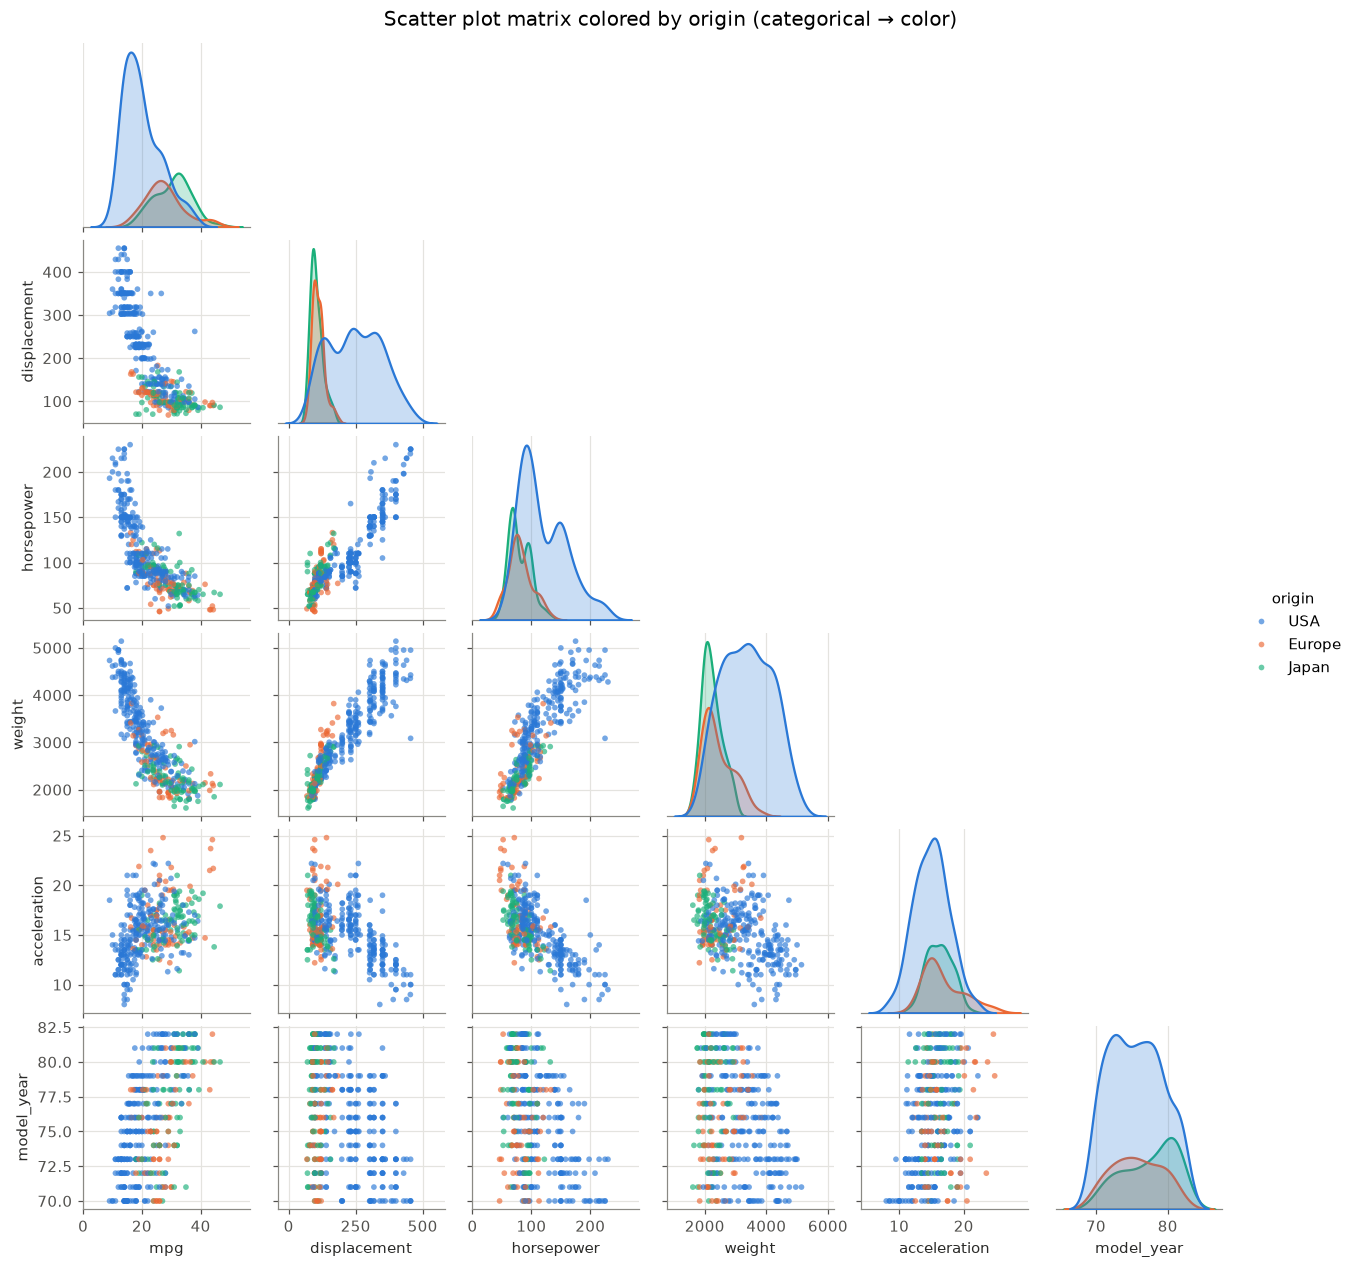

In [15]:
g = sns.pairplot(df[NUM + ["origin"]].dropna(), hue="origin", hue_order=ORIGIN_ORDER, palette=ORIGIN_COLORS,
                 corner=True, height=1.9, plot_kws=dict(s=14, alpha=0.65, edgecolor="none"),
                 diag_kind="kde", diag_kws=dict(fill=True, alpha=0.25, linewidth=1.5))
g.figure.suptitle("Scatter plot matrix colored by origin (categorical → color)", y=1.01, fontsize=13)
plt.show()

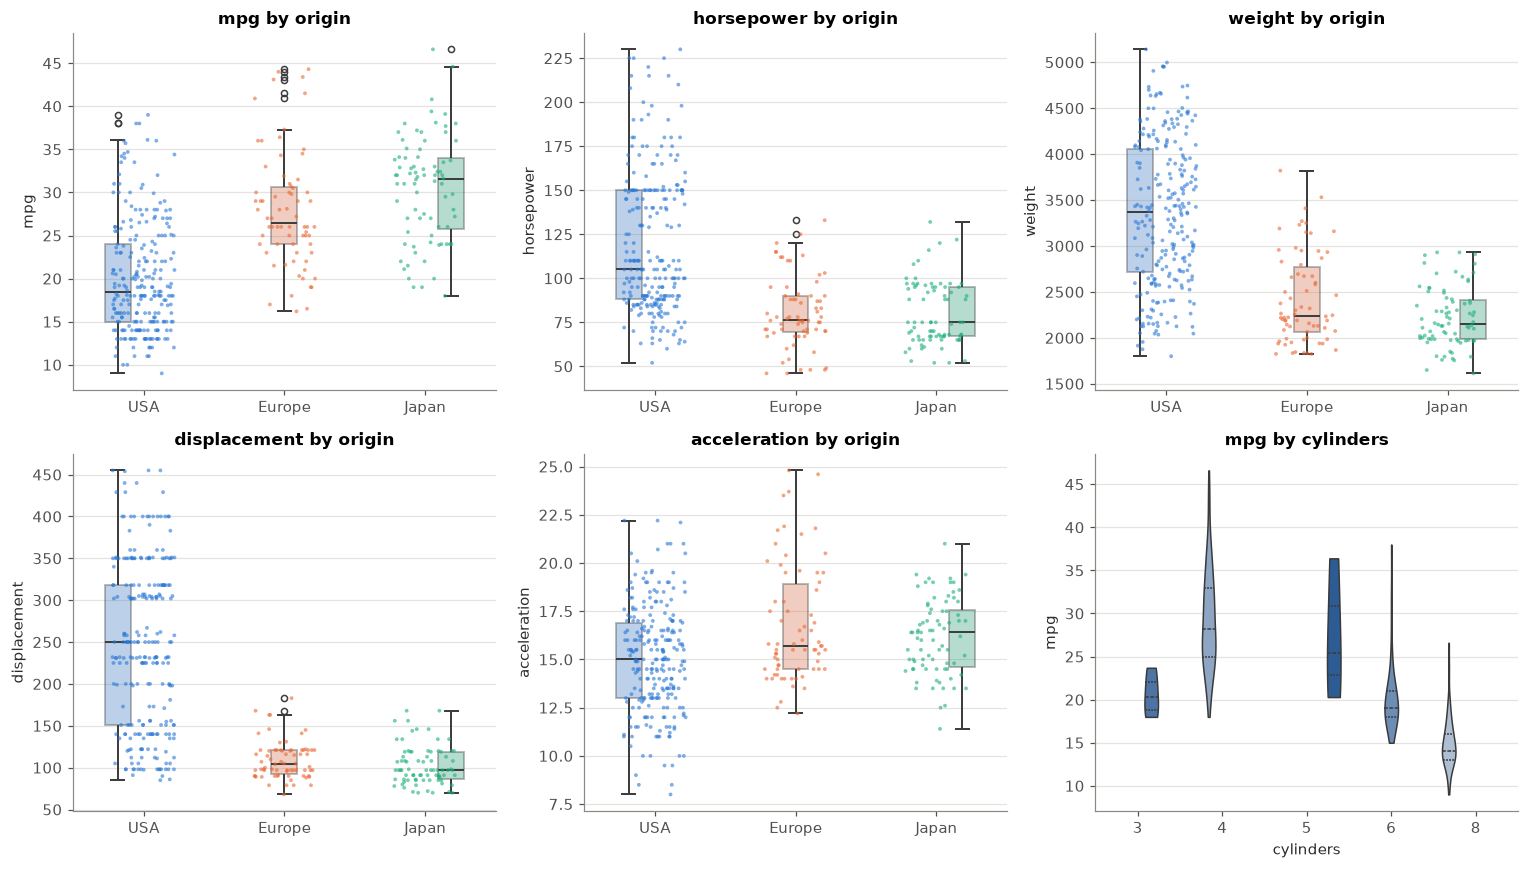

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, c in zip(axes.flat, ["mpg", "horsepower", "weight", "displacement", "acceleration"]):
    sns.boxplot(data=df, x="origin", y=c, hue="origin", palette=ORIGIN_COLORS, order=ORIGIN_ORDER, legend=False,
                width=0.55, linewidth=1.3, fliersize=4, ax=ax, boxprops=dict(alpha=0.35))
    sns.stripplot(data=df, x="origin", y=c, hue="origin", palette=ORIGIN_COLORS, order=ORIGIN_ORDER, legend=False,
                  size=2.5, alpha=0.6, jitter=0.22, ax=ax)
    ax.set(title=f"{c} by origin", xlabel="")
sns.violinplot(data=df, x="cylinders", y="mpg", hue="cylinders", palette=CYL_COLORS, legend=False,
               inner="quartile", linewidth=1, ax=axes[1, 2], cut=0)
axes[1, 2].set(title="mpg by cylinders")
fig.tight_layout()

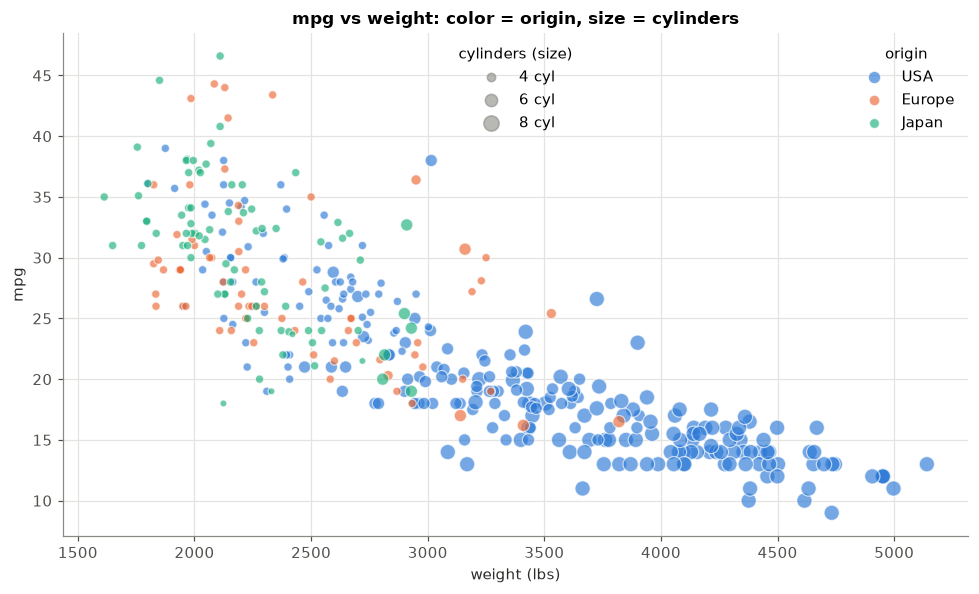

In [17]:
fig, ax = plt.subplots(figsize=(9, 5.5))
d = df.dropna(subset=["horsepower"])
sizes = d["cylinders"].astype(int).map({3: 20, 4: 30, 5: 45, 6: 65, 8: 100})
for o in ORIGIN_ORDER:
    m = d["origin"] == o
    ax.scatter(d.loc[m, "weight"], d.loc[m, "mpg"], s=sizes[m], color=ORIGIN_COLORS[o], alpha=0.65,
               edgecolor="white", linewidth=0.8, label=o)
leg1 = ax.legend(title="origin", frameon=False, loc="upper right")
ax.add_artist(leg1)
for k, s in {4: 30, 6: 65, 8: 100}.items():
    ax.scatter([], [], s=s, color=NEUTRAL, alpha=0.6, label=f"{k} cyl")
h, l = ax.get_legend_handles_labels()
ax.legend(h[3:], l[3:], title="cylinders (size)", frameon=False, loc="upper center")
ax.set(title="mpg vs weight: color = origin, size = cylinders", xlabel="weight (lbs)", ylabel="mpg")
fig.tight_layout()

What coloring and grouping by category show:
* **The groups in the plain scatter matrix are the categories.** Colored by origin, American cars (blue)
  fill the heavy, powerful, low-mpg corner of every panel, and Japanese/European cars overlap in the light,
  efficient corner. The two bumps in the `displacement` and `horsepower` histograms are mostly the
  American group vs everyone else.
* **Box plots:** the median mpg increases USA < Europe < Japan, and the US spread is much wider because the US group
  includes both small 4-cylinder cars and large V8s. The `horsepower` outliers from §3 are all American. European cars have the
  highest *mean* 0–60 time (16.8 s), pulled up by the slow diesels that were the high acceleration outliers in §3.
* **Violin by cylinders:** mpg drops in steps from 4 → 6 → 8 cylinders (medians ≈ 28 → 19 → 14).
  The 3- and 5-cylinder groups are too small to draw firm conclusions about.
* **Combined scatter:** along the weight axis, the colors and sizes move together. Once you know a car's weight, origin adds little
  extra information about mpg. Weight (or engine size) is the main driver, and origin works mostly through it.

## 9. Conclusions

1. **Data quality:** clean overall. There are 6 missing `horsepower` values and a few spelling errors in make names; all outliers
   are real cars (big V8s, diesels, one very efficient Mazda), so **none were removed**.
2. **Distributions:** `mpg`, `horsepower`, `displacement` and `weight` are right-skewed (mean > median);
   `acceleration` is close to normal; `model_year` is close to uniform. `displacement` is multi-modal because of the cylinder groups.
3. **NIST assumptions:** the 4-plot shows `mpg` is *not* a fixed-location, randomly ordered, normally distributed
   series. It drifts with model year and is skewed, so a model should include `model_year` and probably
   use log(mpg) or gallons per mile.
4. **Relationships:** size variables (`weight`, `displacement`, `horsepower`) are strongly related to each
   other (r ≈ 0.9) and have a strong, curved negative relationship with `mpg`. Fuel economy improved steadily from 1970 to 1982.
5. **Categories:** `origin` and `cylinders` are strongly linked (all V8s are American). Much of the large
   mpg gap between US and imported cars is a difference in engine/vehicle size, not origin itself.